# Exploring and Charting the Dataset:

## Imports:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Initializing the dataframe:

In [2]:
def create_df():
    df = pd.read_csv("../Dataset/HollywoodsMostProfitableStories.csv")
    df = df.rename(columns={"Audience  score %" : "Audience Score %"})
    df = df.dropna()

    df = df.astype({"Audience Score %" : np.int8, "Rotten Tomatoes %" : np.int8, "Profitability" : np.float32, "Worldwide Gross" : np.float64})
    df["Profitability"], df["Worldwide Gross"] = np.round(df["Profitability"], 2), np.round(df["Worldwide Gross"], 2)
    return df

df = create_df()
# ['Film', 'Genre', 'Lead Studio', 'Audience Score %', 'Profitability' 'Rotten Tomatoes %', 'Worldwide Gross', 'Year']

## Exploring the dataset:

### Release Years:

In [3]:
print(f"The films' release years range from: {min(df['Year'])} - {max(df['Year'])}")

The films' release years range from: 2007 - 2011


### Production Studios:
#### All Production Studios: 

In [4]:
sorted_LS_df = df.sort_values(by='Lead Studio')

for e in sorted_LS_df['Lead Studio'].drop_duplicates():
    print(e)

20th Century Fox
CBS
Disney
Fox
Independent
Lionsgate
New Line
Paramount
Sony
Summit
The Weinstein Company
Universal
Warner Bros.


#### Number of Movies per Studio:

In [5]:
for e in sorted_LS_df['Lead Studio'].drop_duplicates():
    number_of_movies = len(sorted_LS_df[sorted_LS_df['Lead Studio'] == e])

    if number_of_movies > 1:
        print(f"{e}: {number_of_movies} Movies")
    else:
        print(f"{e}: {number_of_movies} Movie")

20th Century Fox: 2 Movies
CBS: 1 Movie
Disney: 6 Movies
Fox: 6 Movies
Independent: 17 Movies
Lionsgate: 2 Movies
New Line: 1 Movie
Paramount: 4 Movies
Sony: 4 Movies
Summit: 5 Movies
The Weinstein Company: 3 Movies
Universal: 6 Movies
Warner Bros.: 12 Movies


### The Movie Genres:
#### All Movie Genres:

In [6]:
sorted_G_df = df.sort_values(by='Genre')

print(sorted_G_df['Genre'].drop_duplicates().to_string(index=False))

   Action
Animation
   Comedy
    Drama
  Fantasy
  Romance


#### Number of Movies per Genre:

In [7]:
for e in sorted_G_df['Genre'].drop_duplicates():
    number_of_movies = len(sorted_G_df[sorted_G_df['Genre'] == e])

    if number_of_movies > 1:
        print(f"{e}: {number_of_movies} Movies")
    else:
        print(f"{e}: {number_of_movies} Movie")

Action: 1 Movie
Animation: 3 Movies
Comedy: 38 Movies
Drama: 13 Movies
Fantasy: 1 Movie
Romance: 13 Movies


## Charting the Data:

### Worldwide Gross per Genre:

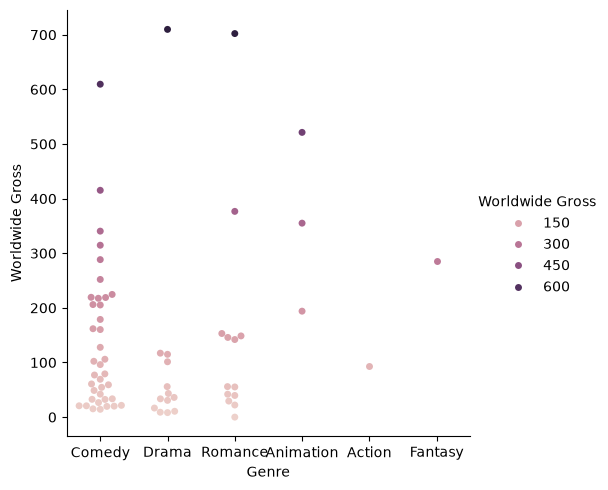

In [8]:
sns.catplot(data=df, kind="swarm", x="Genre", y="Worldwide Gross", hue="Worldwide Gross")

## Gross by year of comedy movies:

### It is important to note that the dataset contains only one comedy movie in 2011, which is why I opted to remove it for the sake of cleaner and clearer charts.

<Axes: xlabel='Year', ylabel='Worldwide Gross'>

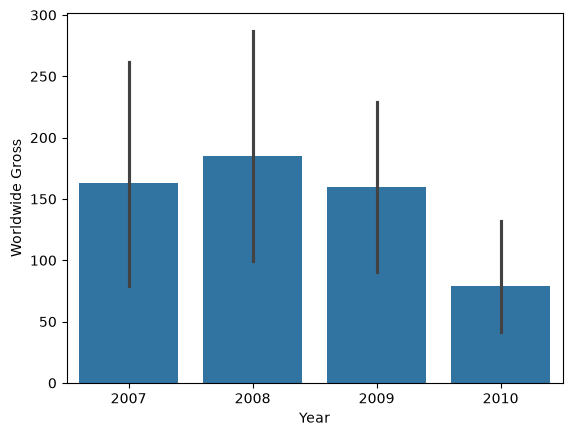

In [14]:
df_onlycoms = df[df["Genre"] == 'Comedy']
df_onlycoms = df_onlycoms[df_onlycoms['Year'] != 2011]
sns.barplot(data=df_onlycoms, x="Year", y="Worldwide Gross")

## Average Audience Score per Year:

<Axes: xlabel='Year', ylabel='Audience Score %'>

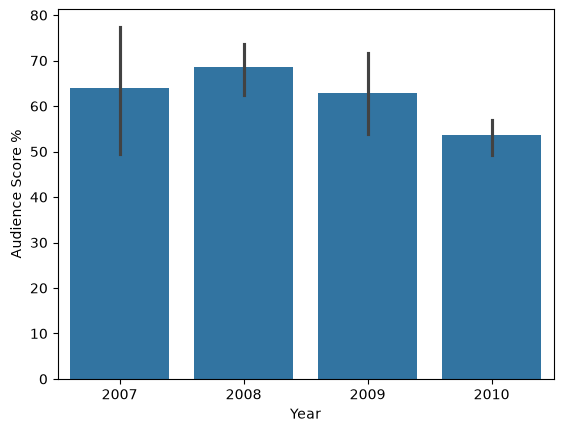

In [15]:
df_onlycoms = df[df["Genre"] == 'Comedy']
df_onlycoms = df_onlycoms[df_onlycoms['Year'] != 2011]
sns.barplot(data=df_onlycoms, x="Year", y="Audience Score %")

## Average Rotten Tomatoes Score per Year:

<Axes: xlabel='Year', ylabel='Rotten Tomatoes %'>

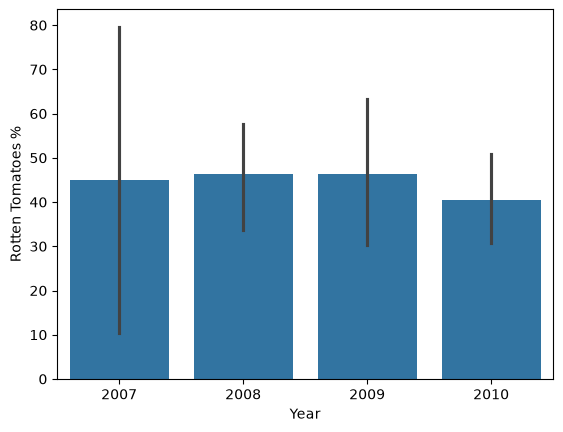

In [16]:
df_onlycoms = df[df["Genre"] == 'Comedy']
df_onlycoms = df_onlycoms[df_onlycoms['Year'] != 2011]
sns.barplot(data=df_onlycoms, x="Year", y="Rotten Tomatoes %")